In [2]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from functools import reduce
import calendar

In [3]:
BASE_DIR = "clean_dataset"

table_date = [
    'sales_pipeline'
]

date_columns = {
    name: ['engage_date', 'close_date']
    for name in table_date}


dfs = {}

for file in os.listdir(BASE_DIR):

    if file.endswith(".csv"):

        path = os.path.join(BASE_DIR, file)
        name = file.replace(".csv", "")

        dates = date_columns.get(name, None)

     
        df = pd.read_csv(
            path,
            parse_dates=dates
        )

        dfs[name] = df



In [4]:
df_sales_pipeline = dfs['sales_pipeline']
df_products = dfs['products']
df_sales_pipeline_all_eng = df_sales_pipeline[~df_sales_pipeline['engage_date'].isna()]
df_sales_pipeline_Won = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Won']
df_sales_pipeline_Lost = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Lost']
df_sales_pipeline_Lost = pd.merge(df_sales_pipeline_Lost,df_products[['product','sales_price']],on ='product',how='left')
df_sales_pipeline_Lost.rename(
    columns={'sales_price': 'close_values_lost'},
    inplace=True
)
df_sales_pipeline_closed = df_sales_pipeline[~df_sales_pipeline['close_date'].isna()]
df_sales_pipeline_Pros = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Prospecting']
df_sales_pipeline_engaging = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Engaging']

>> Opportunity Overview

In [29]:
print(f"Total opportunity : {df_sales_pipeline['opportunity_id'].nunique()}")
stage_distribution = (
    df_sales_pipeline
    .groupby('deal_stage')['opportunity_id']
    .nunique()
    .reset_index(name='total_opportunity')
)

stage_distribution['percentage'] = (
    stage_distribution['total_opportunity'] /
    stage_distribution['total_opportunity'].sum() * 100
)

df_sales_pipeline_closed['duration_to_close'] = (df_sales_pipeline_closed['close_date']-df_sales_pipeline_closed['engage_date']).dt.days
print(f"Average Duration to Close : {df_sales_pipeline_closed['duration_to_close'].mean().round(0)} days")

df_sales_pipeline_Won['day_diff_won'] = (df_sales_pipeline_Won['close_date']-df_sales_pipeline_Won['engage_date']).dt.days
print(f"Average Duration to Win : {df_sales_pipeline_Won['day_diff_won'].mean().round(0)} days")
print(f"Average Value of Opportunity Won :{df_sales_pipeline_Won['close_value'].mean().round(0)}")

df_sales_pipeline_Lost['day_diff_lost'] = (df_sales_pipeline_Lost['close_date']-df_sales_pipeline_Lost['engage_date']).dt.days
print(f"Average Duration to Lost : {df_sales_pipeline_Lost['day_diff_lost'].mean().round(0)} days")


display(stage_distribution.sort_values('percentage', ascending=False))

print(f"opportunity prospecting stage without account data : {len(df_sales_pipeline_Pros[df_sales_pipeline_Pros['account']=='Unidentified'])}")

Total opportunity : 8800
Average Duration to Close : 48.0 days
Average Duration to Win : 52.0 days
Average Value of Opportunity Won :2361.0
Average Duration to Lost : 41.0 days


,deal_stage,total_opportunity,percentage
3,Won,4238,48.159091
1,Lost,2473,28.102273
0,Engaging,1589,18.056818
2,Prospecting,500,5.681818


opportunity prospecting stage without account data : 337


data menujukkan bahwa dari keseluruuhan opportunity yang ada saat ini ada 1589 opportunity yang masih berstatus engaging dan 500 lainnya berstatus prospecting dengan 337 opportunity tersebut belum memiliki tujuan account.

48% opportunity yang ada berakhir denagn status Won sementara 28% lainnya berakhir dengan status Lost

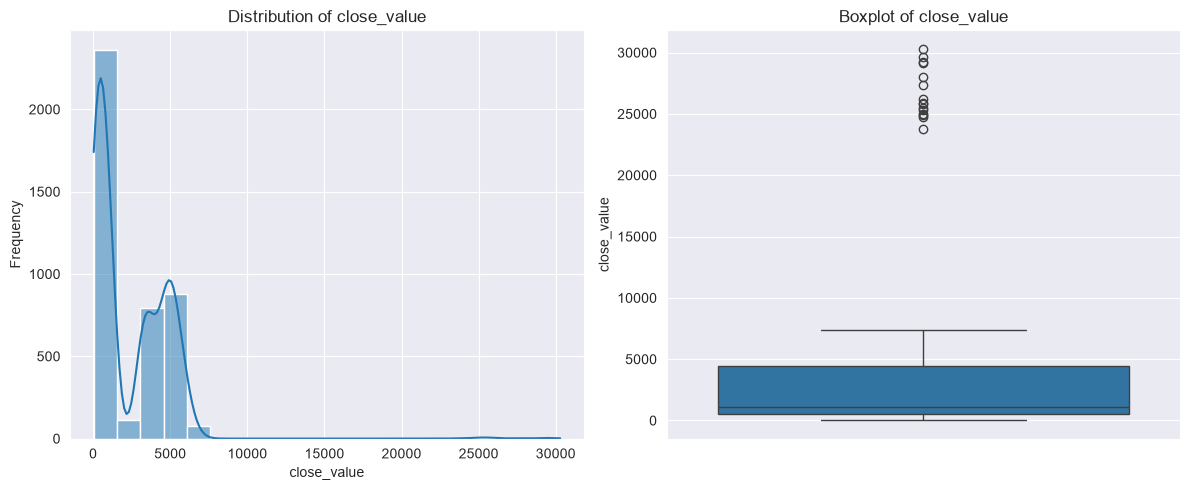

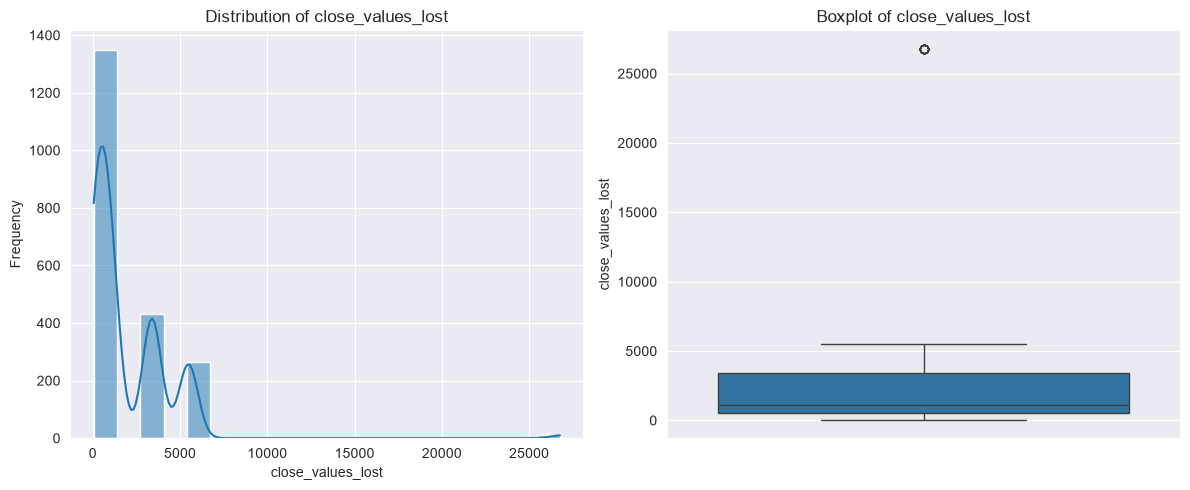

In [30]:
data = {
    'Won': (df_sales_pipeline_Won, 'close_value'),
    'Lost': (df_sales_pipeline_Lost, 'close_values_lost')
}

sns.set_style("darkgrid")

for stage, (df, column) in data.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.histplot(
        data=df,
        x =column,
        bins=20,
        kde=True,
        ax=axes[0])

    axes[0].set_title(f'Distribution of {column}')
    axes[0].set_xlabel(f'{column}')
    axes[0].set_ylabel('Frequency')

    sns.boxplot(\
        data= df[column],
        ax=axes[1])
    
    axes[1].set_title(f'Boxplot of {column}')
    axes[1].set_ylabel(f'{column}')
    
    
    #plt.ylim(0, 8000)
    plt.tight_layout()
    plt.show()


Revenue yang didapat dari keseluruhan opportunity yang win maupun lost sebagian besar terkonsentrasi di nilai yang kecil. Khusus untuk opportunity lost, 75% di antaranya bernilai di bawah ~$3.300, dan hampir seluruh opportunity (baik win maupun lost) berpusat di bawah nilai $5.000, dengan beberapa anomali outlier ukuran besar.

In [ ]:

def monthly_report(df, column, name):
    results = (
        df
        .groupby([
            df[column].dt.year.rename('year'),
            df[column].dt.month.rename('month')
        ])
        .agg(**{
            f'total_{name}': ('opportunity_id', 'nunique')
        }).reset_index()
    )

    return results

monthly_engaged = monthly_report(df_sales_pipeline_all_eng,'engage_date','engaged')
monthly_won = monthly_report(df_sales_pipeline_Won,'close_date','won')
monthly_lost = monthly_report(df_sales_pipeline_Lost,'close_date','lost')

df_monthly = [
    monthly_engaged,
    monthly_won,
    monthly_lost]

monthly_report = reduce(
    lambda df1, df2: pd.merge(
        df1, df2,
        on=['year','month'],
        how='outer'
    ),
    df_monthly
)


cols = ['total_won', 'total_lost']

monthly_report[cols] = monthly_report[cols].astype('Int64')

monthly_report['y-m'] = (
    monthly_report['year'].astype(str)+
    "-"+
    monthly_report['month'].astype(str)
)

monthly_report['year-month'] = (
    pd.to_datetime(monthly_report['year'].astype(str)+
    "-"+
    monthly_report['month'].astype(str),format='%Y-%m')
)

monthly_report[['total_won', 'total_lost']] = (
    monthly_report[['total_won', 'total_lost']].fillna(0)
)


#monthly revenue
monthly_revenue = (
    df_sales_pipeline_Won
    .groupby(
        [df_sales_pipeline_Won['close_date'].dt.year.rename('year'),
         df_sales_pipeline_Won['close_date'].dt.month.rename('month')]
    )
    .agg(total_value = ('close_value','sum'))
    .reset_index()
)

monthly_report_summary = (
    pd.merge(
        monthly_report
        ,monthly_revenue
        ,on =['year','month']
        ,how='outer')
)

monthly_report_summary['total_value'] = monthly_report_summary['total_value'].fillna(0)

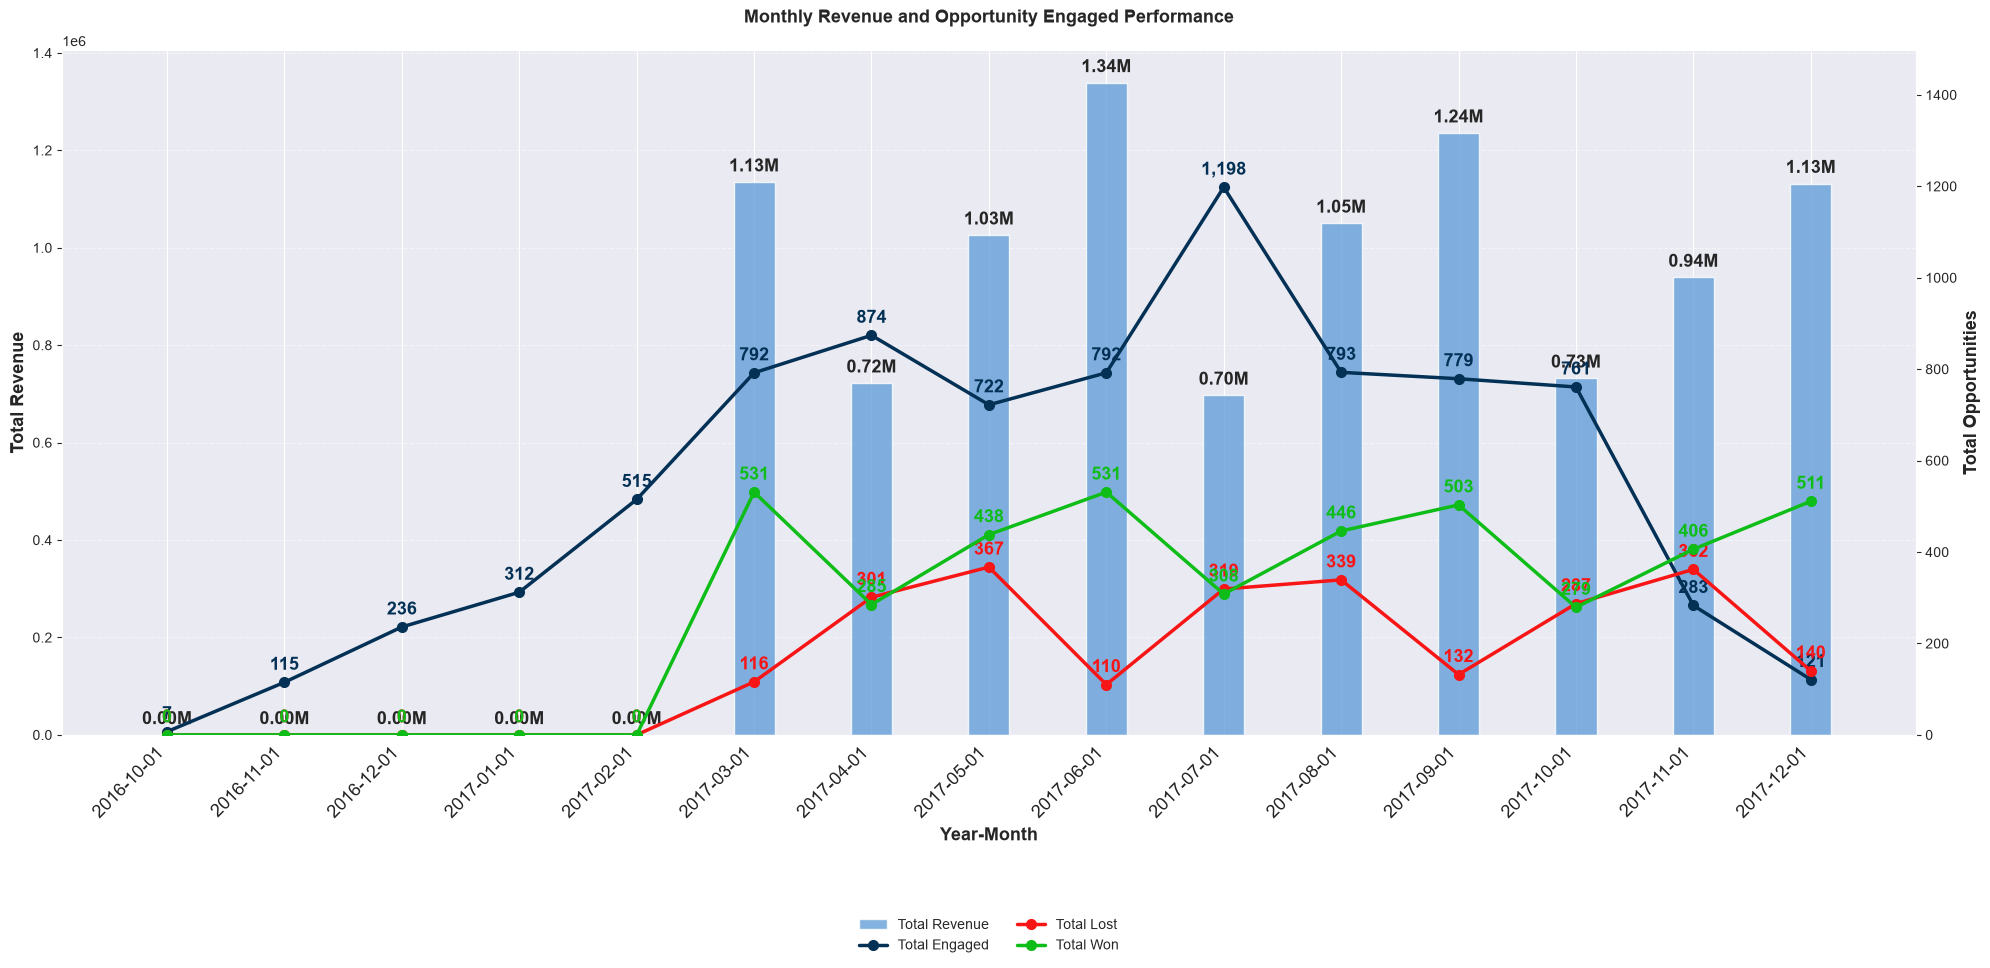

In [8]:

sns.set_style("darkgrid")

fig, ax1 = plt.subplots(figsize=(20,10))

x = np.arange(len(monthly_report_summary["year-month"]))
width = 0.35

# bar chart
bars = ax1.bar(
    x,
    monthly_report_summary["total_value"],
    width,
    color="#649FDA",
    alpha=0.8,
    label="Total Revenue",
    zorder=2
)

ax1.set_ylabel(
    "Total Revenue",
    fontsize=13,
    fontweight="bold"
)

ax1.set_xlabel(
    "Year-Month",
    fontsize=13,
    fontweight="bold"
)

ax1.set_xticks(x)
ax1.set_xticklabels(
    monthly_report_summary["year-month"].astype(str),
    fontsize=13,
    rotation=45,
    ha="right"
)

ax1.grid(axis="y", linestyle="--", alpha=0.5)


for bar in bars:
    height = bar.get_height()

    ax1.annotate(
        f"{height/1e6:.2f}M",
        (bar.get_x() + bar.get_width()/2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )

# Sec y-axis
ax2 = ax1.twinx()

line_color1 = "#033055"
line_color2 = "#F71515"
line_color3 = "#0FBD18"

metrics = [
    ("total_engaged", line_color1, "Total Engaged"),
    ("total_lost", line_color2, "Total Lost"),
    ("total_won", line_color3, "Total Won")
]


for column, color, label in metrics:

    ax2.plot(
        x,
        monthly_report_summary[column],
        color=color,
        marker="o",
        linewidth=2.5,
        markersize=7,
        label=label,
        zorder=3
    )

    
    for i, value in enumerate(monthly_report_summary[column]):

        if pd.notna(value):
            ax2.annotate(
                f"{int(value):,}",
                (x[i], value),
                textcoords="offset points",
                xytext=(0, 9),
                ha="center",
                color=color,
                fontsize=13,
                fontweight="bold"
            )

ax2.set_ylabel(
    "Total Opportunities",
    fontsize=13,
    fontweight="bold"
)

ax2.set_ylim(
    0,
    monthly_report_summary["total_engaged"].max() * 1.25
)

ax2.grid(False)


plt.title(
    "Monthly Revenue and Opportunity Engaged Performance",
    fontsize=13,
    fontweight="bold",
    pad=20
)

# Legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    bbox_to_anchor=(0.5, -0.25),
    loc="upper center",
    ncol=2,
    frameon=True,
    facecolor="white",
    edgecolor="none"
)

sns.despine(ax=ax1, top=True, right=False)

plt.tight_layout()
plt.show()


>> Breakdown Opportunity by Deal Stage

In [ ]:
df_sales